"""
Simple Hierarchical Multi-Agent System with Groq
===============================================
Shows how to organize agents in teams with team leaders.

Structure:
- CEO (top level)
  - Research Team Leader
    - Data Researcher
    - Market Researcher
  - Writing Team Leader
    - Technical Writer
    - Summary Writer

In [1]:
import os
from typing import TypedDict, Annotated, List, Literal
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langchain_groq import ChatGroq
from langchain_core.tools import tool
from langchain_community.tools.tavily_search import TavilySearchResults
from langgraph.graph import StateGraph, END
from langgraph.prebuilt import create_react_agent
from langgraph.checkpoint.memory import MemorySaver

C:\Users\antoc\AppData\Local\Temp\ipykernel_28212\924501044.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


In [2]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

In [3]:
from langgraph.graph import StateGraph, END, MessagesState
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver

In [4]:

## Define the state
class AgenState(MessagesState):
    next_agent: str 

In [6]:
from langchain.chat_models import init_chat_model

llm=init_chat_model("openai:gpt-3.5-turbo")
llm

ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.3', 'langchain-openai': '1.7.0'}}, profile={'name': 'GPT-3.5-turbo', 'status': 'deprecated', 'release_date': '2023-03-01', 'last_updated': '2023-11-06', 'open_weights': False, 'max_input_tokens': 16385, 'max_output_tokens': 4096, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': False, 'structured_output': False, 'attachment': False, 'temperature': True, 'image_url_inputs': False, 'pdf_inputs': False, 'pdf_tool_message': False, 'image_tool_message': False, 'tool_choice': True, 'tool_call_streaming': True}, client=<openai.resources.chat.completions.completions.Completions object at 0x000002911E847980>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x000002911E912600>, root_client=<openai.Open

In [7]:
from typing import TypedDict, Literal
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage
from langgraph.graph import StateGraph, END

class HierarchicalState(TypedDict, total=False):
    messages: list[BaseMessage]
    current_task: str
    next_agent: str
    research_data: str
    market_analysis: str
    combined_research: str
    technical_report: str
    executive_summary: str
    final_report: str
    task_complete: bool

In [8]:
def data_researcher(state: HierarchicalState) -> dict:
    task = state["current_task"]
    response = llm.invoke([
        ("system", "You are the Data Researcher. Identify relevant facts, metrics, evidence, and data points. Do not invent precise statistics; flag uncertainty."),
        ("human", f"Research the data and evidence needed for this task: {task}")
    ])
    print("Data Researcher completed.")
    return {
        "research_data": response.content,
        "messages": [AIMessage(content="Data Researcher completed the evidence-gathering task.")],
        "next_agent": "market_researcher",
    }

In [9]:
def market_researcher(state: HierarchicalState) -> dict:
    task = state["current_task"]
    data = state.get("research_data", "")
    response = llm.invoke([
        ("system", "You are the Market Researcher. Analyze market context, trends, stakeholders, competitors, opportunities, and risks. Clearly distinguish assumptions from facts."),
        ("human", f"Task: {task}\n\nData research findings:\n{data}\n\nProvide market research and implications.")
    ])
    print("Market Researcher completed.")
    return {
        "market_analysis": response.content,
        "messages": [AIMessage(content="Market Researcher completed the market analysis.")],
        "next_agent": "research_leader",
    }


In [10]:
def technical_writer(state: HierarchicalState) -> dict:
    task = state["current_task"]
    research = state.get("combined_research", "")
    response = llm.invoke([
        ("system", "You are the Technical Writer. Produce a structured, detailed report using the supplied research. Do not add unsupported claims."),
        ("human", f"Task: {task}\n\nResearch findings:\n{research}\n\nWrite the detailed report with headings, findings, implications, and recommendations.")
    ])
    print("Technical Writer completed.")
    return {
        "technical_report": response.content,
        "messages": [AIMessage(content="Technical Writer completed the detailed report.")],
        "next_agent": "summary_writer",
    }

In [11]:
def summary_writer(state: HierarchicalState) -> dict:
    task = state["current_task"]
    research = state.get("combined_research", "")
    technical = state.get("technical_report", "")
    response = llm.invoke([
        ("system", "You are the Summary Writer. Create a concise executive summary for a busy decision-maker. Preserve the main conclusions and important caveats."),
        ("human", f"Task: {task}\n\nResearch:\n{research}\n\nTechnical report:\n{technical}\n\nWrite an executive summary with key findings and recommended actions.")
    ])
    print("Summary Writer completed.")
    return {
        "executive_summary": response.content,
        "messages": [AIMessage(content="Summary Writer completed the executive summary.")],
        "next_agent": "writing_leader",
    }

In [ ]:
def research_team_leader(state: HierarchicalState) -> dict:
    # Delegate first to Data Researcher, then Market Researcher.
    if not state.get("research_data"):
        print("Research Team Leader → Data Researcher")
        return {
            "messages": [AIMessage(content="Research Team Leader delegated data gathering to Data Researcher.")],
            "next_agent": "data_researcher",
        }

    if not state.get("market_analysis"):
        print("Research Team Leader → Market Researcher")
        return {
            "messages": [AIMessage(content="Research Team Leader delegated market analysis to Market Researcher.")],
            "next_agent": "market_researcher",
        }

    # Combine both research outputs before handing control back to CEO.
    combined = (
        "DATA RESEARCH\n" + state.get("research_data", "") +
        "\n\nMARKET RESEARCH\n" + state.get("market_analysis", "")
    )
    print("Research Team Leader consolidated findings.")
    return {
        "combined_research": combined,
        "messages": [AIMessage(content="Research Team Leader consolidated the research and returned it to the CEO.")],
        "next_agent": "ceo",
    }

In [12]:
def writing_team_leader(state: HierarchicalState) -> dict:
    if not state.get("technical_report"):
        print("👥 Writing Team Leader → Technical Writer")
        return {
            "messages": [AIMessage(content="Writing Team Leader delegated the detailed report to Technical Writer.")],
            "next_agent": "technical_writer",
        }

    if not state.get("executive_summary"):
        print("👥 Writing Team Leader → Summary Writer")
        return {
            "messages": [AIMessage(content="Writing Team Leader delegated the executive summary to Summary Writer.")],
            "next_agent": "summary_writer",
        }

    print("👥 Writing Team Leader returned both deliverables to the CEO.")
    return {
        "messages": [AIMessage(content="Writing Team Leader completed both writing tasks and returned the deliverables to the CEO.")],
        "next_agent": "ceo",
    }

In [15]:
def ceo_agent(state: HierarchicalState) -> dict:
    task = state.get("current_task", "")
    if not state.get("combined_research"):
        print("🏢 CEO → Research Team Leader")
        return {
            "messages": [AIMessage(content="CEO assigned the task to the Research Team Leader.")],
            "next_agent": "research_leader",
        }

    if not state.get("technical_report") or not state.get("executive_summary"):
        print("🏢 CEO → Writing Team Leader")
        return {
            "messages": [AIMessage(content="CEO assigned the research findings to the Writing Team Leader.")],
            "next_agent": "writing_leader",
        }

    print("🏢 CEO reviewing final deliverables.")
    review = llm.invoke([
        ("system", "You are the CEO reviewing a team's deliverables. Produce the final response with an executive summary first, then the detailed report. Resolve repetition, preserve caveats, and do not invent facts."),
        ("human", f"Task: {task}\n\nEXECUTIVE SUMMARY:\n{state.get('executive_summary', '')}\n\nTECHNICAL REPORT:\n{state.get('technical_report', '')}")
    ])
    final_report = review.content
    return {
        "final_report": final_report,
        "task_complete": True,
        "next_agent": "end",
        "messages": [AIMessage(content="CEO reviewed the deliverables. The final report is ready.")],
    }


def router(state: HierarchicalState) -> Literal[
    "ceo", "research_leader", "data_researcher", "market_researcher",
    "writing_leader", "technical_writer", "summary_writer", "__end__"
]:
    if state.get("task_complete") or state.get("next_agent") == "end":
        return END

    allowed = {
        "ceo", "research_leader", "data_researcher", "market_researcher",
        "writing_leader", "technical_writer", "summary_writer"
    }
    next_agent = state.get("next_agent", "ceo")
    return next_agent if next_agent in allowed else "ceo" 

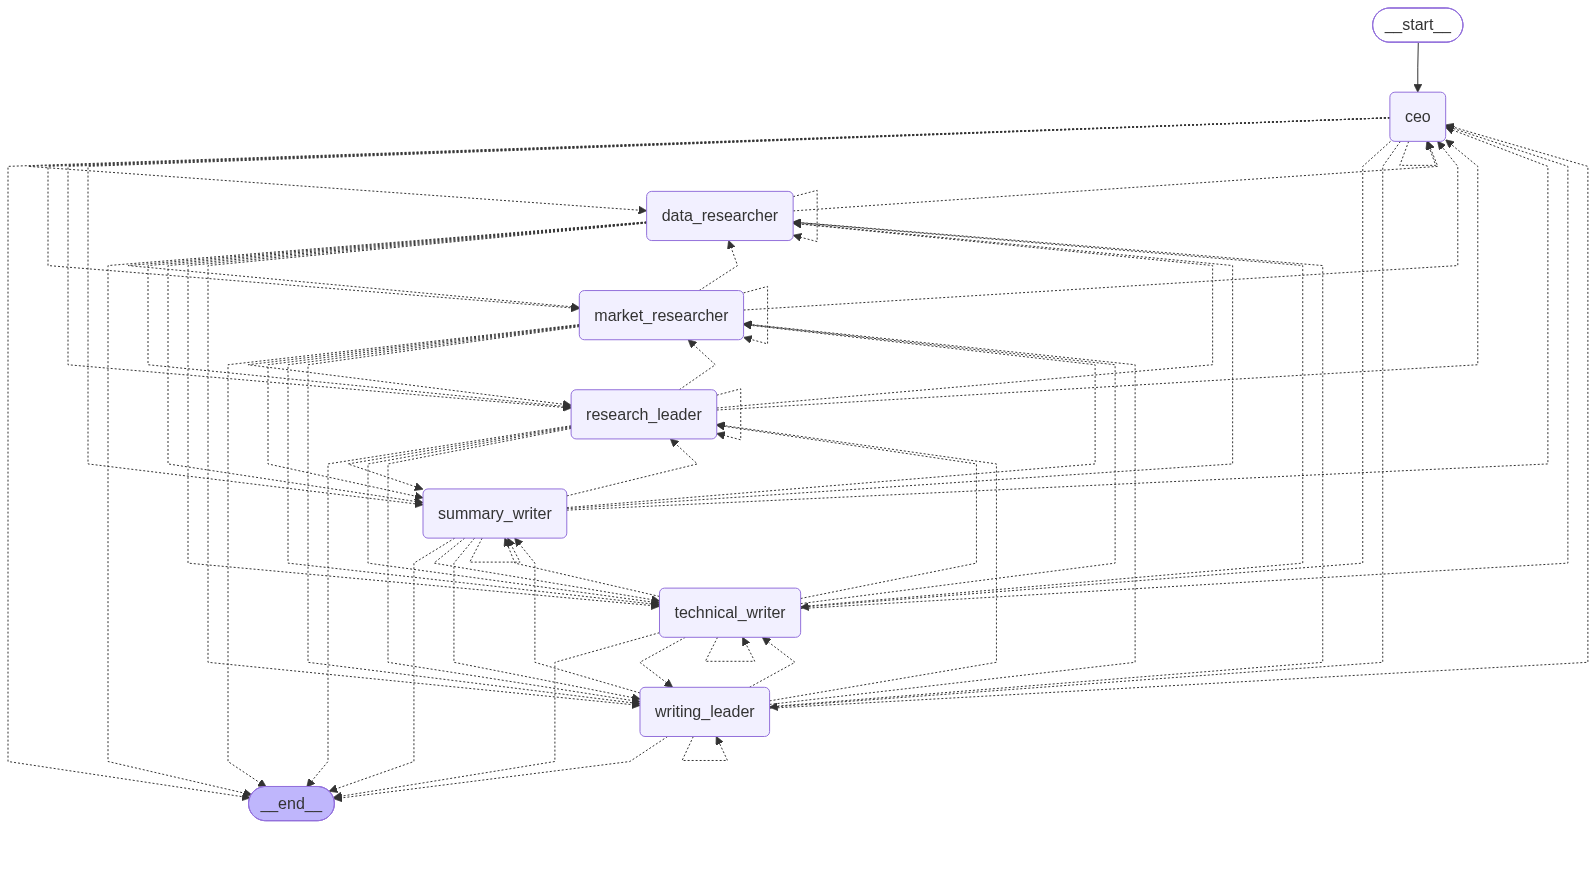

In [16]:
workflow = StateGraph(HierarchicalState)

workflow.add_node("ceo", ceo_agent)
workflow.add_node("research_leader", research_team_leader)
workflow.add_node("data_researcher", data_researcher)
workflow.add_node("market_researcher", market_researcher)
workflow.add_node("writing_leader", writing_team_leader)
workflow.add_node("technical_writer", technical_writer)
workflow.add_node("summary_writer", summary_writer)

workflow.set_entry_point("ceo")

for node in [
    "ceo", "research_leader", "data_researcher", "market_researcher",
    "writing_leader", "technical_writer", "summary_writer"
]:
    workflow.add_conditional_edges(
        node,
        router,
        {
            "ceo": "ceo",
            "research_leader": "research_leader",
            "data_researcher": "data_researcher",
            "market_researcher": "market_researcher",
            "writing_leader": "writing_leader",
            "technical_writer": "technical_writer",
            "summary_writer": "summary_writer",
            END: END,
        },
    )

graph = workflow.compile()
graph

In [17]:
task = "Research the benefits, risks, and business use cases of agentic AI in retail."

response = graph.invoke({
    "messages": [HumanMessage(content=task)],
    "current_task": task,
    "next_agent": "ceo",
    "research_data": "",
    "market_analysis": "",
    "combined_research": "",
    "technical_report": "",
    "executive_summary": "",
    "final_report": "",
    "task_complete": False,
})

print(response["final_report"])

🏢 CEO → Research Team Leader
Research Team Leader → Data Researcher
Data Researcher completed.
Market Researcher completed.
Research Team Leader consolidated findings.
🏢 CEO → Writing Team Leader
👥 Writing Team Leader → Technical Writer
Technical Writer completed.
Summary Writer completed.
👥 Writing Team Leader returned both deliverables to the CEO.
🏢 CEO reviewing final deliverables.
Subject: Executive Review of Agentic AI in Retail Report

**Executive Summary:**

Agentic AI holds great promise for retailers by enhancing customer experiences, boosting operational efficiency, and enabling data-driven decisions. However, potential risks such as privacy concerns, bias, security vulnerabilities, and the importance of human oversight must be effectively managed to capitalize on its benefits.

**Key Findings:**
- **Benefits:** Personalized experiences, operational efficiency, predictive analytics, and real-time insights are key advantages.
- **Risks:** Privacy issues, bias, security threats